# Fase 3 — Preparación de los datos (CRISP-DM)
Partición por sujeto sin fuga y normalización por canal. Usa `src/prep.py` y `src/config.py`.
No se entrena ningún modelo en esta fase.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
from config import set_global_seed, SEED, SPLITS_FILE
from data_io import load_or_cache, load_activity_labels, CHANNELS
from prep import (build_and_save_splits, mask_by_subjects, assert_disjoint_subjects,
                  ChannelStandardizer)
set_global_seed(SEED)
Xtr, ytr, s_tr = load_or_cache("train"); Xte, yte, s_te = load_or_cache("test")
LABELS = load_activity_labels(); NAMES = [LABELS[i] for i in sorted(LABELS)]
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

## 1. Construcción de particiones (por sujeto, estratificadas)

In [2]:
sp = build_and_save_splits(ytr, s_tr, s_te)
print(json.dumps(sp, indent=1))

{
 "seed": 42,
 "holdout_subjects": [
  5,
  7,
  22,
  25
 ],
 "dev_subjects": [
  1,
  3,
  6,
  8,
  11,
  14,
  15,
  16,
  17,
  19,
  21,
  23,
  26,
  27,
  28,
  29,
  30
 ],
 "test_subjects": [
  2,
  4,
  9,
  10,
  12,
  13,
  18,
  20,
  24
 ],
 "cv_folds": [
  {
   "fold": 0,
   "train_subjects": [
    1,
    3,
    6,
    11,
    15,
    16,
    19,
    30
   ],
   "val_subjects": [
    8,
    14,
    17,
    21,
    23,
    26,
    27,
    28,
    29
   ]
  },
  {
   "fold": 1,
   "train_subjects": [
    8,
    14,
    17,
    21,
    23,
    26,
    27,
    28,
    29
   ],
   "val_subjects": [
    1,
    3,
    6,
    11,
    15,
    16,
    19,
    30
   ]
  }
 ]
}


## 2. Verificación anti-fuga (aserciones)

In [3]:
m_hold = mask_by_subjects(s_tr, sp["holdout_subjects"]); m_dev = mask_by_subjects(s_tr, sp["dev_subjects"])
assert (m_hold ^ m_dev).all(), "cada ventana de train debe estar en dev XOR holdout"
assert_disjoint_subjects(s_tr[m_dev], s_tr[m_hold], "dev", "holdout")
assert_disjoint_subjects(s_tr, s_te, "train", "test")
for f in sp["cv_folds"]:
    assert not set(f["train_subjects"]) & set(f["val_subjects"])
    assert set(f["train_subjects"]) | set(f["val_subjects"]) == set(sp["dev_subjects"])
    assert not (set(f["train_subjects"]) | set(f["val_subjects"])) & set(sp["holdout_subjects"])
print("OK: ningún sujeto compartido entre particiones; holdout fuera de la CV; test intacto.")

OK: ningún sujeto compartido entre particiones; holdout fuera de la CV; test intacto.


## 3. Tamaño y distribución de clases por partición

In [4]:
def summ(name, m_or_subj, y, s):
    m = mask_by_subjects(s, m_or_subj)
    d = pd.Series(y[m]).map(LABELS).value_counts(normalize=True).reindex(NAMES) * 100
    return {"particion": name, "sujetos": len(m_or_subj), "ventanas": int(m.sum()), **d.round(2).to_dict()}
rows = [summ("DEV (CV+final)", sp["dev_subjects"], ytr, s_tr),
        summ("HOLD-OUT val (c)", sp["holdout_subjects"], ytr, s_tr)]
dev_idx = np.where(m_dev)[0]
for f in sp["cv_folds"]:
    rows.append(summ(f"CV fold{f['fold']} train", f["train_subjects"], ytr, s_tr))
    rows.append(summ(f"CV fold{f['fold']} val", f["val_subjects"], ytr, s_tr))
rows.append(summ("TEST oficial (d,f)", sp["test_subjects"], yte, s_te))
tab = pd.DataFrame(rows).set_index("particion"); display(tab)
tab.to_csv(FIG / "tabla_particiones.csv")
print("Desv. máx. de % de clase vs DEV (puntos %):",
      round((tab[NAMES] - tab.loc["DEV (CV+final)", NAMES]).abs().max().max(), 2))

,sujetos,ventanas,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
particion,,,,,,,,
DEV (CV+final),17,6012,16.52,14.44,13.27,17.75,18.76,19.26
HOLD-OUT val (c),4,1340,17.39,15.30,14.03,16.34,18.36,18.58
CV fold0 train,8,2766,17.75,15.22,13.81,16.99,17.39,18.84
CV fold0 val,9,3246,15.47,13.77,12.82,18.39,19.93,19.62
CV fold1 train,9,3246,15.47,13.77,12.82,18.39,19.93,19.62
CV fold1 val,8,2766,17.75,15.22,13.81,16.99,17.39,18.84
"TEST oficial (d,f)",9,2947,16.83,15.98,14.25,16.66,18.05,18.22


Desv. máx. de % de clase vs DEV (puntos %): 1.54


## 4. Normalización por canal sin fuga
Se ilustra con el fold 0: `fit` solo con el train del fold y `transform` en su validación.
El train debe quedar con media 0 y desviación 1 exactas; la validación, aproximadas (ese desfase es la señal de que no hubo fuga).

In [5]:
f0 = sp["cv_folds"][0]
mtr = mask_by_subjects(s_tr, f0["train_subjects"]); mva = mask_by_subjects(s_tr, f0["val_subjects"])
sc = ChannelStandardizer().fit(Xtr[mtr])
Ztr, Zva = sc.transform(Xtr[mtr]), sc.transform(Xtr[mva])
chk = pd.DataFrame({"mu_fit": sc.mean_, "sd_fit": sc.std_,
                    "train_media": Ztr.mean((0,1)), "train_desv": Ztr.std((0,1)),
                    "val_media": Zva.mean((0,1)), "val_desv": Zva.std((0,1))}, index=CHANNELS)
display(chk.round(4))
assert np.allclose(Ztr.mean((0,1)), 0, atol=1e-3) and np.allclose(Ztr.std((0,1)), 1, atol=1e-3)
# El scaler NO debe coincidir con uno ajustado sobre train+val (prueba de que no se usó val)
sc_leak = ChannelStandardizer().fit(Xtr[mtr | mva])
print("Dif. máx. |mu_fold - mu_train+val| =", float(np.abs(sc.mean_ - sc_leak.mean_).max()))
chk.to_csv(FIG / "tabla_normalizacion_fold0.csv")

,mu_fit,sd_fit,train_media,train_desv,val_media,val_desv
body_acc_x,-0.0008,0.2017,-0.0000,1.0,0.0012,0.9324
body_acc_y,-0.0002,0.1253,0.0000,1.0,-0.0007,0.9456
body_acc_z,-0.0007,0.1000,0.0000,1.0,0.0073,1.1349
body_gyro_x,-0.0044,0.4316,-0.0000,1.0,0.0152,0.8767
body_gyro_y,0.0008,0.3953,-0.0000,1.0,-0.0055,1.0142
body_gyro_z,0.0000,0.2377,-0.0000,1.0,-0.0033,1.1773
total_acc_x,0.8144,0.4074,-0.0001,1.0,-0.0444,1.0095
total_acc_y,0.0360,0.4287,-0.0000,1.0,-0.0567,0.8450
total_acc_z,0.0942,0.2956,-0.0000,1.0,-0.1367,1.3948


Dif. máx. |mu_fold - mu_train+val| = 0.02181580662727356


In [6]:
# Prueba de ida y vuelta de guardado/carga (lo usará la interfaz)
import tempfile
tmp = Path(tempfile.mkdtemp()) / "scaler_demo.json"; sc.save(tmp)   # fuera del proyecto
sc2 = ChannelStandardizer.load(tmp); assert np.allclose(sc2.transform(Xtr[:5]), sc.transform(Xtr[:5]))
print("save/load OK")

save/load OK


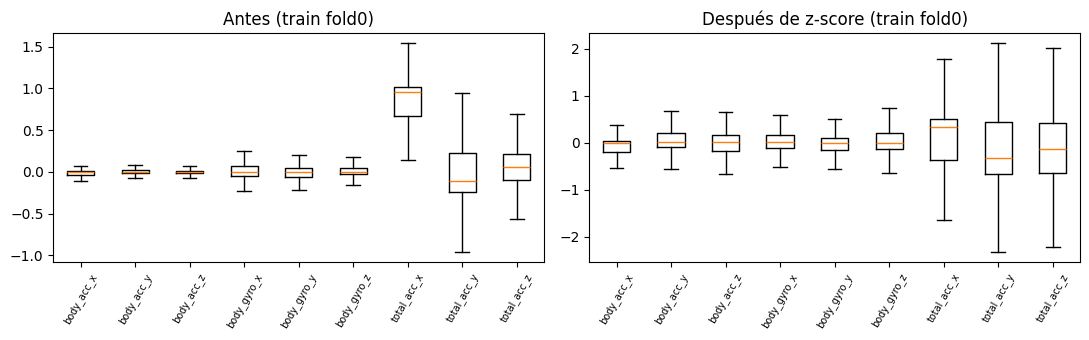

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].boxplot([Xtr[mtr][..., k].ravel()[::50] for k in range(9)], showfliers=False)
axs[0].set_title("Antes (train fold0)"); axs[0].set_xticks(range(1,10), CHANNELS, rotation=60, fontsize=7)
axs[1].boxplot([Ztr[..., k].ravel()[::50] for k in range(9)], showfliers=False)
axs[1].set_title("Después de z-score (train fold0)"); axs[1].set_xticks(range(1,10), CHANNELS, rotation=60, fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig01_normalizacion.png")